# Data Preparation

In this notebook, we prepare the Bike Sharing data for modeling. The raw file is left unchanged: all transformations are applied to a copy of the data.

### 1. Data Quality Decisions

**_1.1 Zero Wind Speed_**

In the EDA, `windspeed` was equal to 0 in about 12.5% of records, and the next smallest value was 0.0896. Zeros may mean very low wind, or they may mean that wind speed was not measured. Before choosing how to handle them, we check how these records are distributed, starting with the year.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv('../data/raw/hour.csv')
data_prep = data.copy()
data_prep['dteday'] = pd.to_datetime(data_prep['dteday'])

In [3]:
data_prep['windspeed_zero'] = (data_prep['windspeed'] == 0).astype(int)

print('Shape:', data_prep.shape)
print('Zero wind speed records:', data_prep['windspeed_zero'].sum())

Shape: (17379, 18)
Zero wind speed records: 2180


In [4]:
data_prep['year'] = data_prep['yr'].map({0: 2011, 1: 2012})

In [5]:
zero_by_year = data_prep.groupby('year')['windspeed_zero'].agg(
    zero_records='sum',
    total_records='count'
)
zero_by_year['zero_share_%'] = (
    zero_by_year['zero_records'] / zero_by_year['total_records'] * 100
).round(2)

print(zero_by_year)
print('Total records check:', zero_by_year['total_records'].sum())

      zero_records  total_records  zero_share_%
year                                           
2011          1107           8645         12.81
2012          1073           8734         12.29
Total records check: 17379


**_Zero Wind Speed by Month_**

The share of zero wind speed records is almost the same in 2011 (12.81%) and 2012 (12.29%), so zeros are not concentrated in one year. To check whether they cluster in particular periods, we calculate the share of zero records for each month of each year.

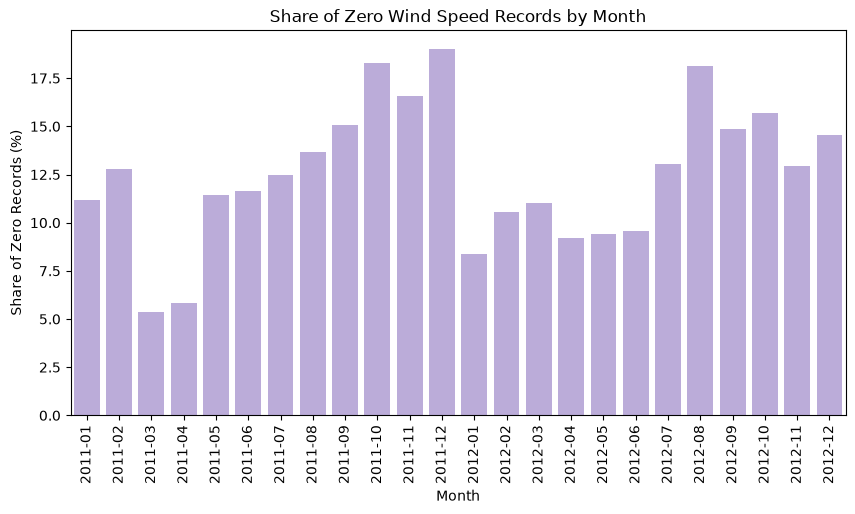

count    24.00
mean     12.53
std       3.64
min       5.34
25%      10.31
50%      12.64
75%      14.91
max      19.03
Name: zero_share_%, dtype: float64


In [6]:
data_prep['year_month'] = data_prep['dteday'].dt.to_period('M').astype(str)

zero_by_month = (
    data_prep.groupby('year_month')['windspeed_zero']
    .mean()
    .mul(100)
    .reset_index(name='zero_share_%')
)

plt.figure(figsize=(10, 5))
sns.barplot(data=zero_by_month, x='year_month', y='zero_share_%', color='#B9A5E0')
plt.title('Share of Zero Wind Speed Records by Month')
plt.xlabel('Month')
plt.ylabel('Share of Zero Records (%)')
plt.xticks(rotation=90)
plt.show()

print(zero_by_month['zero_share_%'].describe().round(2))

**_Zero Wind Speed by Hour_**

The share of zero wind speed records varies strongly by month, from about 5% to about 19%, and drops sharply between December 2011 and January 2012. Zero wind speed may mean either calm conditions or a reading below the sensor threshold, because no values between 0 and 0.0896 are present. If zeros are mostly real calm, they should depend on the time of day. We check the share of zero records for each hour.

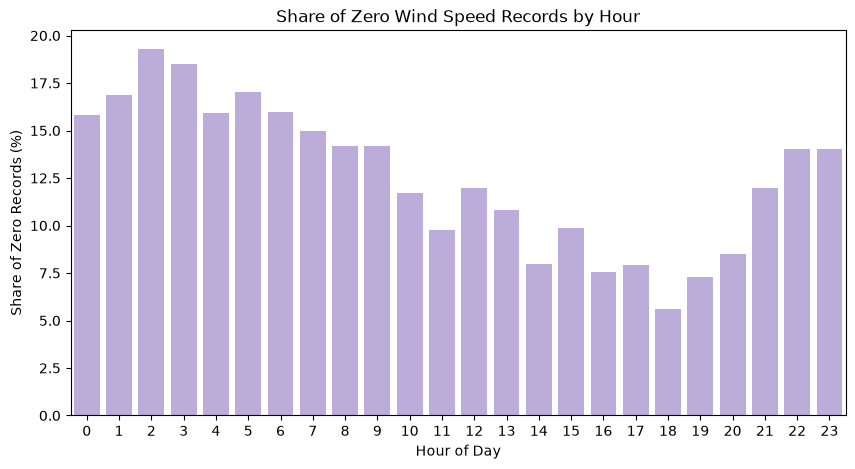

count    24.00
mean     12.57
std       3.89
min       5.63
25%       9.45
50%      12.98
75%      15.86
max      19.30
Name: zero_share_%, dtype: float64


In [7]:
zero_by_hour = (
    data_prep.groupby('hr')['windspeed_zero']
    .mean()
    .mul(100)
    .reset_index(name='zero_share_%')
)

plt.figure(figsize=(10, 5))
sns.barplot(data=zero_by_hour, x='hr', y='zero_share_%', color='#B9A5E0')
plt.title('Share of Zero Wind Speed Records by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Share of Zero Records (%)')
plt.show()

print(zero_by_hour['zero_share_%'].describe().round(2))

**_Rental Demand With and Without Zero Wind Speed_**

Zero wind speed records are more frequent at night (about 16-19% between 0:00 and 6:00) and less frequent in the afternoon and evening (about 6-10%). This pattern follows the typical daily cycle of wind, so zeros probably mostly reflect very weak wind rather than random missing values. However, it also means that the overall difference in average rentals between zero and non-zero records (about 160.6 vs 193.6) is partly explained by the time of day. To avoid this, we compare average rentals for the two groups within each hour.

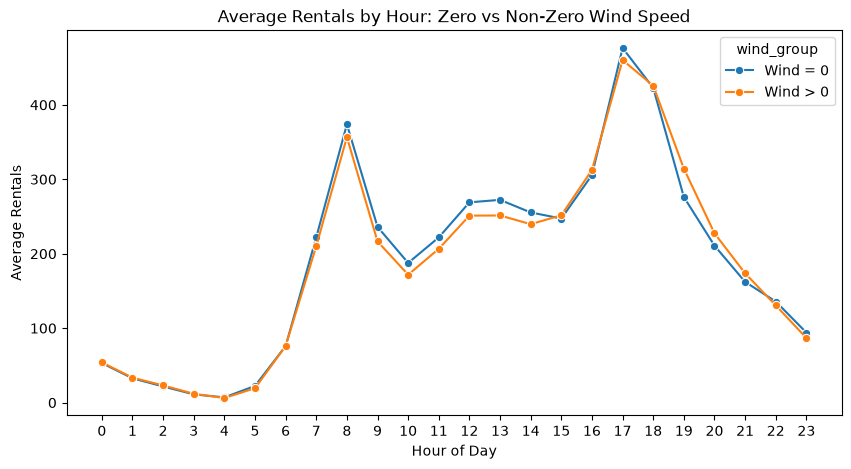

wind_group
Wind = 0     41
Wind > 0    568
dtype: int64


In [8]:
data_prep['wind_group'] = data_prep['windspeed_zero'].map({0: 'Wind > 0', 1: 'Wind = 0'})

cnt_by_hour_wind = (
    data_prep.groupby(['hr', 'wind_group'])['cnt']
    .mean()
    .reset_index(name='avg_rentals')
)

plt.figure(figsize=(10, 5))
sns.lineplot(data=cnt_by_hour_wind, x='hr', y='avg_rentals', hue='wind_group', marker='o')
plt.title('Average Rentals by Hour: Zero vs Non-Zero Wind Speed')
plt.xlabel('Hour of Day')
plt.ylabel('Average Rentals')
plt.xticks(range(0, 24))
plt.show()

group_sizes = data_prep.groupby(['hr', 'wind_group']).size().unstack()
print(group_sizes.min())

**_Decision on Zero Wind Speed_**

Within the same hour, average rentals with zero and non-zero wind speed are close, and the differences have no consistent direction. The overall gap (about 160.6 vs 193.6) is largely explained by zeros being more frequent at night, when demand is low anyway. This check controls only for the hour, not for season or temperature, so it does not prove that zero wind has no effect.

Decision: keep `windspeed` unchanged, keep zeros as they are, and keep the `windspeed_zero` flag as a candidate feature. Whether it is useful will be checked during model comparison.

**_1.2 Zero Humidity_**

In the EDA, `hum` was equal to 0 in 22 records (about 0.13% of the data), all from a single date, 2011-03-10. A relative humidity of exactly 0 is physically implausible, so these values look like a data error rather than a real measurement. First, we check that zeros appear only on this date, and then we look at this day hour by hour.

In [9]:
hum_zero = data_prep[data_prep['hum'] == 0]

print('Zero humidity records:', len(hum_zero))
print('Dates with zero humidity:', hum_zero['dteday'].dt.date.unique())

Zero humidity records: 22
Dates with zero humidity: [datetime.date(2011, 3, 10)]


In [10]:
day_check = data_prep[data_prep['dteday'] == '2011-03-10'][['dteday', 'hr', 'hum', 'temp', 'windspeed', 'weathersit', 'cnt']]

print('Records on 2011-03-10:', len(day_check))
print(day_check.to_string(index=False))

Records on 2011-03-10: 22
    dteday  hr  hum  temp  windspeed  weathersit  cnt
2011-03-10   0  0.0  0.34     0.2537           3    3
2011-03-10   1  0.0  0.34     0.2537           3    2
2011-03-10   2  0.0  0.34     0.2537           3    1
2011-03-10   5  0.0  0.36     0.1940           3    3
2011-03-10   6  0.0  0.36     0.3284           3   12
2011-03-10   7  0.0  0.38     0.2239           3   37
2011-03-10   8  0.0  0.38     0.2836           3   44
2011-03-10   9  0.0  0.40     0.2239           3   24
2011-03-10  10  0.0  0.40     0.1642           3   17
2011-03-10  11  0.0  0.40     0.2537           3   11
2011-03-10  12  0.0  0.42     0.2239           3   34
2011-03-10  13  0.0  0.42     0.2239           3   12
2011-03-10  14  0.0  0.44     0.2985           3   12
2011-03-10  15  0.0  0.44     0.2239           3   14
2011-03-10  16  0.0  0.42     0.2537           3   21
2011-03-10  17  0.0  0.44     0.3881           2  111
2011-03-10  18  0.0  0.44     0.3582           3   82
20

All 22 records of 2011-03-10 have `hum = 0`, so the whole day is affected, while `temp`, `windspeed` and `cnt` look plausible. In this day, 20 of 22 records have `weathersit = 3` (light rain or snow) and the other two have `weathersit = 2`, so zero humidity contradicts the weather description. Hours 3 and 4 are also missing from this day. Therefore, the zeros look like missing values and not real measurements.

Dropping the day would remove 22 records of demand in rainy weather, and keeping zeros would create a false link between zero humidity and low demand. To choose a replacement, we first check humidity on neighboring days and in records with similar weather.

In [11]:
neighbors = data_prep[
    (data_prep['dteday'] >= '2011-03-07') & (data_prep['dteday'] <= '2011-03-13')
]

daily_hum = neighbors.groupby('dteday').agg(
    avg_hum=('hum', 'mean'),
    min_hum=('hum', 'min'),
    max_hum=('hum', 'max'),
    records=('hum', 'count'),
    main_weather=('weathersit', lambda s: s.mode().iloc[0])
).round(2)

print(daily_hum)

            avg_hum  min_hum  max_hum  records  main_weather
dteday                                                      
2011-03-07     0.55     0.29     1.00       23             1
2011-03-08     0.42     0.18     0.69       24             1
2011-03-09     0.78     0.52     0.93       24             2
2011-03-10     0.00     0.00     0.00       22             3
2011-03-11     0.65     0.49     1.00       23             1
2011-03-12     0.59     0.41     0.75       24             1
2011-03-13     0.53     0.38     0.76       23             1


In [12]:
hum_rain = data_prep[(data_prep['weathersit'] == 3) & (data_prep['hum'] > 0)]['hum']

print('Records with weathersit = 3 and hum > 0:', len(hum_rain))
print(hum_rain.describe().round(3))

Records with weathersit = 3 and hum > 0: 1399
count    1399.000
mean        0.839
std         0.123
min         0.350
25%         0.790
50%         0.870
75%         0.930
max         1.000
Name: hum, dtype: float64


Humidity on neighboring days varies widely (daily averages from about 0.42 to 0.78), so using neighbors would be a rough guess. Humidity in records with light rain or snow (`weathersit = 3`, zeros excluded) is high and fairly stable: the median is 0.87 and the middle half of values lies between 0.79 and 0.93.

Decision: treat the zeros on 2011-03-10 as missing values, replace them with `NaN`, and fill them with the median humidity of records with the same `weathersit` (zeros excluded). We keep the 22 records because they carry information about demand in rainy weather. All 22 records get nearly the same humidity, so this is an approximation, not a recovery of the real values. The median is calculated on the full dataset, which is a minor limitation because only 0.13% of records are affected.

In [13]:
data_prep.loc[data_prep['hum'] == 0, 'hum'] = np.nan

print('Missing hum after replacement:', data_prep['hum'].isna().sum())

hum_median_by_weather = data_prep.groupby('weathersit')['hum'].median()
print(hum_median_by_weather)

Missing hum after replacement: 22
weathersit
1    0.56
2    0.71
3    0.87
4    0.86
Name: hum, dtype: float64


In [14]:
data_prep['hum'] = data_prep['hum'].fillna(
    data_prep['weathersit'].map(hum_median_by_weather)
)

print('Missing hum after filling:', data_prep['hum'].isna().sum())
print('Zero hum records:', (data_prep['hum'] == 0).sum())
print(data_prep.loc[data_prep['dteday'] == '2011-03-10', 'hum'].value_counts())

Missing hum after filling: 0
Zero hum records: 0
hum
0.87    20
0.71     2
Name: count, dtype: int64


**_1.3 Constant Apparent Temperature_**

In the EDA, `atemp` was equal to 0.2424 in all 24 hours of 2012-08-17, while `temp` changed during the day (24 records, about 0.14% of the data). Apparent temperature should follow the actual temperature, so a constant value looks like a recording error. First, we look at this day hour by hour.

In [15]:
day_atemp = data_prep[data_prep['dteday'] == '2012-08-17'][['dteday', 'hr', 'temp', 'atemp', 'hum', 'windspeed', 'cnt']]

print('Records on 2012-08-17:', len(day_atemp))
print(day_atemp.to_string(index=False))

Records on 2012-08-17: 24
    dteday  hr  temp  atemp  hum  windspeed  cnt
2012-08-17   0  0.68 0.2424 0.57     0.1642   88
2012-08-17   1  0.66 0.2424 0.65     0.1045   54
2012-08-17   2  0.66 0.2424 0.61     0.1343   19
2012-08-17   3  0.64 0.2424 0.65     0.1045    6
2012-08-17   4  0.64 0.2424 0.73     0.1642    9
2012-08-17   5  0.64 0.2424 0.73     0.1045   36
2012-08-17   6  0.62 0.2424 0.78     0.1343  157
2012-08-17   7  0.64 0.2424 0.73     0.1045  379
2012-08-17   8  0.68 0.2424 0.65     0.1343  668
2012-08-17   9  0.70 0.2424 0.58     0.1045  378
2012-08-17  10  0.74 0.2424 0.55     0.1642  231
2012-08-17  11  0.76 0.2424 0.52     0.2836  303
2012-08-17  12  0.82 0.2424 0.41     0.2239  365
2012-08-17  13  0.84 0.2424 0.36     0.3881  357
2012-08-17  14  0.86 0.2424 0.34     0.4179  328
2012-08-17  15  0.86 0.2424 0.30     0.4627  383
2012-08-17  16  0.84 0.2424 0.32     0.4478  488
2012-08-17  17  0.82 0.2424 0.36     0.3284  791
2012-08-17  18  0.82 0.2424 0.38     0.2537

In [16]:
atemp_by_day = data_prep.groupby('dteday')['atemp'].nunique()
constant_days = atemp_by_day[atemp_by_day == 1]

print('Days with constant atemp:', len(constant_days))
print(constant_days)

Days with constant atemp: 4
dteday
2011-09-06    1
2012-08-17    1
2012-10-29    1
2012-12-29    1
Name: atemp, dtype: int64


On 2012-08-17, `atemp` is constant (0.2424) while `temp` ranges from 0.62 to 0.86 (a hot summer day), and the other columns look normal. A check of all dates found three more days where `atemp` does not change during the day: 2011-09-06, 2012-10-29 and 2012-12-29. Therefore, the problem is wider than the single day found in the EDA. We check these days and compare them with the rest of the data.

In [17]:
const_info = (
    data_prep[data_prep['dteday'].isin(constant_days.index)]
    .groupby('dteday')
    .agg(
        records=('hr', 'count'),
        atemp_value=('atemp', 'first'),
        temp_min=('temp', 'min'),
        temp_max=('temp', 'max'),
        avg_rentals=('cnt', 'mean')
    )
    .round(2)
)

print(const_info)
print('Total records in these days:', const_info['records'].sum())

            records  atemp_value  temp_min  temp_max  avg_rentals
dteday                                                           
2011-09-06       23         0.52      0.54      0.54       117.83
2012-08-17       24         0.24      0.62      0.86       297.83
2012-10-29        1         0.44      0.44      0.44        22.00
2012-12-29       24         0.24      0.20      0.30        55.88
Total records in these days: 72


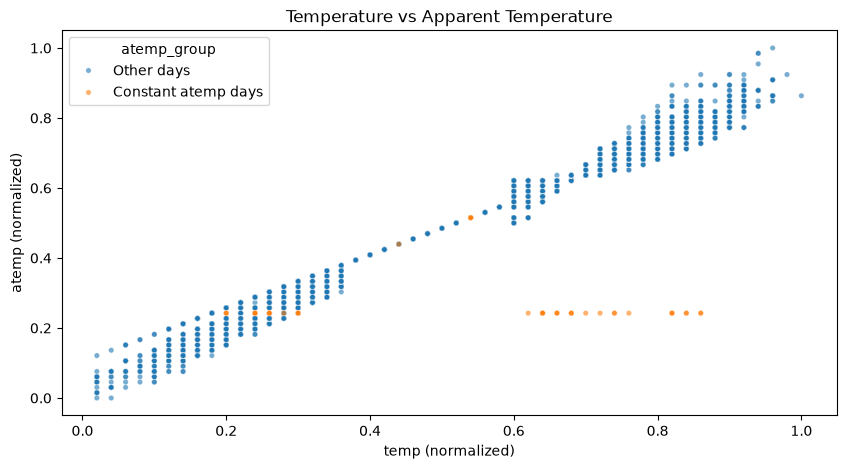

In [18]:
data_prep['atemp_group'] = np.where(
    data_prep['dteday'].isin(constant_days.index),
    'Constant atemp days',
    'Other days'
)

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=data_prep.sort_values('atemp_group', ascending=False),
    x='temp', y='atemp', hue='atemp_group', alpha=0.6, s=15
)
plt.title('Temperature vs Apparent Temperature')
plt.xlabel('temp (normalized)')
plt.ylabel('atemp (normalized)')
plt.show()

The four days found are different cases. On 2012-08-17 `atemp` is constant while `temp` changes widely (0.62 to 0.86), which is clearly an error. On 2012-12-29 `atemp` is also constant while `temp` changes (0.20 to 0.30), which looks like the same problem. On 2011-09-06 both `temp` and `atemp` are constant, so they agree with each other, and 2012-10-29 has only one record, so these two days do not show an `atemp` error.

We check whether the constant value is exactly the same on the two suspicious days, and test how accurately `atemp` can be restored from other columns, using only normal records.

In [19]:
suspect_days = ['2012-08-17', '2012-12-29']

for day in suspect_days:
    part = data_prep[data_prep['dteday'] == day]
    print(day, '| atemp unique values:', part['atemp'].unique(),
          '| temp range:', part['temp'].min(), '-', part['temp'].max())

2012-08-17 | atemp unique values: [0.2424] | temp range: 0.62 - 0.86
2012-12-29 | atemp unique values: [0.2424] | temp range: 0.2 - 0.3


In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Normal records: exclude the 2 suspicious days and the day with filled humidity
bad_days = pd.to_datetime(suspect_days + ['2011-03-10'])
normal = data_prep[~data_prep['dteday'].isin(bad_days)]

for features in (['temp'], ['temp', 'hum', 'windspeed']):
    model = LinearRegression().fit(normal[features], normal['atemp'])
    pred = model.predict(normal[features])
    mae = mean_absolute_error(normal['atemp'], pred)
    print(features, '| MAE:', round(mae, 4), '| R2:', round(model.score(normal[features], normal['atemp']), 4))

['temp'] | MAE: 0.0162 | R2: 0.9845
['temp', 'hum', 'windspeed'] | MAE: 0.0155 | R2: 0.986


On both suspicious days, 2012-08-17 and 2012-12-29, `atemp` is exactly 0.2424 in every hour. The same fixed value on two different days suggests a recording error rather than real weather, so 48 records (about 0.28% of the data) are affected.

To fix them, we check how accurately `atemp` can be restored from other columns, using only normal records. Using `temp` alone gives a mean absolute error of 0.0162 (R² = 0.9845), and adding `hum` and `windspeed` improves it only slightly (0.0155), so we use the simpler model with `temp` only.

Decision: replace `atemp` on the two days with values predicted from `temp`. The days 2011-09-06 and 2012-10-29 are not changed, because `atemp` agrees with `temp` there. `atemp` stays a candidate feature, and the choice between `temp`, `atemp` or both will be made during model comparison. Limitation: the formula is fitted on the full dataset, but it does not use the target `cnt`, so the effect is negligible.

In [21]:
model_atemp = LinearRegression().fit(normal[['temp']], normal['atemp'])

# Mark the 48 records to fix and replace atemp with the predicted value
mask = data_prep['dteday'].isin(pd.to_datetime(suspect_days))
print('Records to fix:', mask.sum())

data_prep.loc[mask, 'atemp'] = model_atemp.predict(data_prep.loc[mask, ['temp']]).round(4)

Records to fix: 48


In [22]:
fixed = data_prep[mask]
print(fixed.groupby('dteday')['atemp'].agg(['min', 'max', 'nunique']).round(3))

# Days with a single atemp value that remain after the fix
atemp_by_day = data_prep.groupby('dteday')['atemp'].nunique()
print('Days with constant atemp left:', (atemp_by_day == 1).sum())
print(atemp_by_day[atemp_by_day == 1])

              min    max  nunique
dteday                           
2012-08-17  0.585  0.798       11
2012-12-29  0.214  0.302        5
Days with constant atemp left: 2
dteday
2011-09-06    1
2012-10-29    1
Name: atemp, dtype: int64


**_1.4 Missing Hours_**

The dataset should contain one record for every hour of 2011 and 2012 (17,544 hours in total), but it has 17,379 records, so 165 hours are missing (115 in 2011 and 50 in 2012). The reason is unknown. We check whether the missing hours are scattered across the period or concentrated on particular days, because this determines whether any action is needed.

In [23]:
full_grid = pd.date_range('2011-01-01 00:00', '2012-12-31 23:00', freq='h')

data_prep['timestamp'] = data_prep['dteday'] + pd.to_timedelta(data_prep['hr'], unit='h')

missing_hours = full_grid.difference(data_prep['timestamp'])

print('Hours in full grid:', len(full_grid))
print('Records in data:', len(data_prep))
print('Missing hours:', len(missing_hours))
print('Duplicated timestamps:', data_prep['timestamp'].duplicated().sum())

Hours in full grid: 17544
Records in data: 17379
Missing hours: 165
Duplicated timestamps: 0


In [24]:
missing_df = pd.DataFrame({'timestamp': missing_hours})
missing_df['date'] = missing_df['timestamp'].dt.date
missing_df['year'] = missing_df['timestamp'].dt.year

print(missing_df.groupby('year').size())

missing_by_day = missing_df.groupby('date').size().sort_values(ascending=False)
print('Days with missing hours:', len(missing_by_day))
print(missing_by_day.head(10))
print(missing_by_day.value_counts().sort_index())

year
2011    115
2012     50
dtype: int64
Days with missing hours: 76
date
2012-10-29    23
2011-01-27    16
2012-10-30    13
2011-01-18    12
2011-01-26     8
2011-08-28     7
2011-08-27     6
2011-02-22     6
2011-02-11     2
2011-01-03     2
dtype: int64
1     62
2      6
6      2
7      1
8      1
12     1
13     1
16     1
23     1
Name: count, dtype: int64


There are 165 missing hours (115 in 2011 and 50 in 2012) in 76 different days. In 62 days only one hour is missing, while 8 days lose 6 or more hours each (91 hours in total, about 55% of all missing hours). Large gaps come in consecutive days, for example 2012-10-29 and 2012-10-30, so they do not look like random recording errors.

In the EDA, the minimum of `cnt` was 1 and no hour had zero rentals. One possible explanation is that hours without rentals were not recorded. If this is true, missing hours should be most frequent at night, when demand is lowest, and large gaps should coincide with extreme weather. We check both.

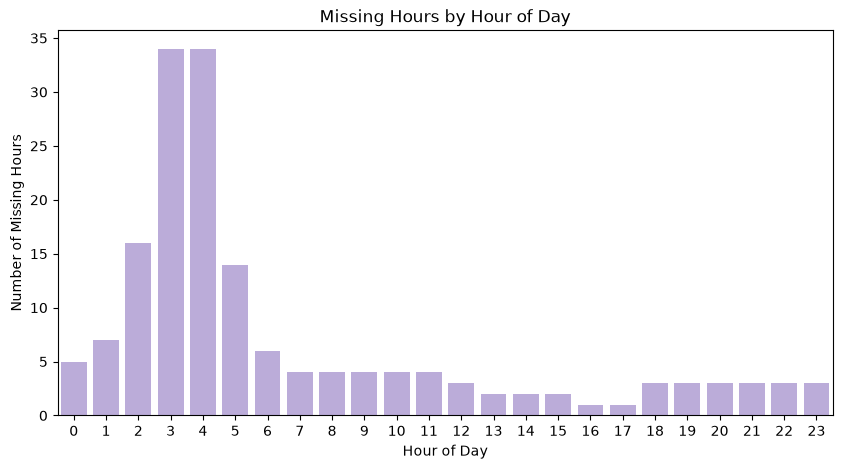

Total: 165


In [25]:
missing_df['hr'] = missing_df['timestamp'].dt.hour

missing_by_hour = missing_df.groupby('hr').size().reindex(range(24), fill_value=0)

plt.figure(figsize=(10, 5))
sns.barplot(x=missing_by_hour.index, y=missing_by_hour.values, color='#B9A5E0')
plt.title('Missing Hours by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Missing Hours')
plt.show()

print('Total:', missing_by_hour.sum())

In [26]:
big_gap_days = missing_by_day[missing_by_day >= 6].index

big_gaps = (
    data_prep[data_prep['dteday'].dt.date.isin(big_gap_days)]
    .groupby(data_prep['dteday'].dt.date)
    .agg(
        records=('hr', 'count'),
        avg_rentals=('cnt', 'mean'),
        main_weather=('weathersit', lambda s: s.mode().iloc[0]),
        avg_windspeed=('windspeed', 'mean')
    )
    .round(2)
)

big_gaps['missing_hours'] = missing_by_day.reindex(big_gaps.index)
print(big_gaps.sort_values('missing_hours', ascending=False))

            records  avg_rentals  main_weather  avg_windspeed  missing_hours
dteday                                                                      
2012-10-29        1        22.00             3           0.36             23
2011-01-27        8        53.88             1           0.11             16
2012-10-30       11        99.64             3           0.21             13
2011-01-18       12        56.92             2           0.15             12
2011-01-26       16        31.62             3           0.29              8
2011-08-28       17       254.94             1           0.30              7
2011-02-22       18        80.56             1           0.20              6
2011-08-27       18        61.94             2           0.38              6


Missing hours are concentrated at night: hours 0-5 account for about 110 of 165 missing hours, with peaks at 3:00 and 4:00 (about 34 each). However, about 47 missing hours fall between 7:00 and 23:00, when demand is never close to zero, so not all gaps can be explained by "no rentals, no record".

Large gaps (6 or more hours) occur in 8 days, 91 hours in total, and come in consecutive days (2012-10-29 and 2012-10-30, 2011-01-26 and 2011-01-27, 2011-08-27 and 2011-08-28). Only some of these days have bad weather (`weathersit` is 3 in three of them), so weather alone does not explain them. The most likely explanation is a mix of hours without rentals at night and system or recording outages. The data cannot confirm this.

To check whether zero demand at night is plausible, we compare the share of missing hours with the share of records at the minimum value `cnt = 1` for each hour.

In [27]:
hour_check = pd.DataFrame({
    'records': data_prep.groupby('hr').size(),
    'missing': missing_by_hour,
    'cnt_eq_1_%': data_prep.groupby('hr')['cnt'].apply(lambda s: (s == 1).mean() * 100)
})
hour_check['missing_%'] = hour_check['missing'] / (hour_check['records'] + hour_check['missing']) * 100

print(hour_check.round(2).loc[0:8])
print('Total records:', hour_check['records'].sum(), '| Total missing:', hour_check['missing'].sum())

    records  missing  cnt_eq_1_%  missing_%
hr                                         
0       726        5        0.00       0.68
1       724        7        0.69       0.96
2       715       16        2.80       2.19
3       697       34        6.89       4.65
4       697       34        9.04       4.65
5       717       14        1.95       1.92
6       725        6        0.83       0.82
7       727        4        0.28       0.55
8       727        4        0.00       0.55
Total records: 17379 | Total missing: 165


Missing hours are concentrated at night: hours 0-5 account for about 110 of 165 missing hours, with peaks at 3:00 and 4:00 (about 34 each). However, 49 missing hours fall between 7:00 and 23:00, when demand is never close to zero, so not all gaps can be explained by "no rentals, no record".

Large gaps (6 or more hours) occur in 8 days, 91 hours in total, and come in consecutive days (2012-10-29 and 2012-10-30, 2011-01-26 and 2011-01-27, 2011-08-27 and 2011-08-28). Only some of these days have bad weather, so weather alone does not explain them.

At night, the share of missing hours follows the share of records with the minimum value `cnt = 1` (at 4:00: 4.65% missing and 9.04% of records equal to 1). This is consistent with some night gaps being hours with zero rentals, but it does not prove it. The remaining gaps look like system or recording outages.

Decision: missing hours are not restored and no rows with `cnt = 0` are added, because the target value would have to be invented. Tabular models do not need a complete hourly grid. The loss is small (165 of 17,544 hours, about 0.94%). If lag features or rolling averages are used later, this decision must be reviewed.

**_1.5 Rare Categories_**

Two groups are small: `weathersit = 4` (heavy rain or snow, only 3 records) and `holiday = 1` (500 records on 21 days). Conclusions based on three records are unreliable, and a separate dummy column for such a category would contain almost no information. We first look at these records directly.

In [28]:
heavy = data_prep[data_prep['weathersit'] == 4][['dteday', 'hr', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt']]
print(heavy.to_string(index=False))

heavy_days = heavy['dteday'].unique()
same_days = data_prep[data_prep['dteday'].isin(heavy_days)]
print(same_days.groupby(['dteday', 'weathersit']).size().unstack(fill_value=0))

    dteday  hr  weathersit  temp  hum  windspeed  cnt
2011-01-26  16           4  0.22 0.93     0.3284   36
2012-01-09  18           4  0.20 0.86     0.0896  164
2012-01-21   1           4  0.14 0.86     0.1940   23
weathersit  1   2   3  4
dteday                  
2011-01-26  0   2  13  1
2012-01-09  6  12   5  1
2012-01-21  1  12  10  1


In [29]:
holidays = (
    data_prep[data_prep['holiday'] == 1]
    .groupby('dteday')
    .agg(
        weekday=('weekday', 'first'),
        workingday=('workingday', 'max'),
        records=('hr', 'count'),
        avg_rentals=('cnt', 'mean')
    )
    .round(1)
)

print('Holiday days:', len(holidays))
print('Holiday records:', holidays['records'].sum())
print(holidays.to_string())
print('Holiday records with workingday = 1:', ((data_prep['holiday'] == 1) & (data_prep['workingday'] == 1)).sum())

Holiday days: 21
Holiday records: 500
            weekday  workingday  records  avg_rentals
dteday                                               
2011-01-17        1           0       24         41.7
2011-02-21        1           0       24         46.1
2011-04-15        5           0       24        130.2
2011-05-30        1           0       24        170.8
2011-07-04        1           0       24        251.8
2011-09-05        1           0       24        139.6
2011-10-10        1           0       24        213.2
2011-11-11        5           0       24        140.3
2011-11-24        4           0       24         62.3
2011-12-26        1           0       23         57.3
2012-01-02        1           0       23         84.8
2012-01-16        1           0       24         95.8
2012-02-20        1           0       23        136.0
2012-04-16        1           0       24        265.4
2012-05-28        1           0       24        251.8
2012-07-04        3           0       24    

The 3 records with `weathersit = 4` are isolated single hours (2011-01-26 16:00, 2012-01-09 18:00, 2012-01-21 01:00), each inside a day where the other hours are mostly category 3 (light rain or snow) or 2 (mist). Humidity is high (0.86-0.93) and temperature is low (0.14-0.22), so they look like ordinary cold, wet weather. Three records cannot be learned reliably, and with a time-based split the category could appear in the test set but not in the training set.

Decision: merge category 4 into category 3, so that 3 now means "rain or snow, light or heavy". The raw file is unchanged.

The 21 holidays (500 records) all have `workingday = 0`, so `workingday` already carries most of the information, and 15 of 21 holidays fall on a Monday. Average rentals differ widely between holidays (41.7 to 308.5), but this mostly reflects season and year, not the holiday itself, and each holiday behaves differently. Decision: keep `holiday` unchanged as a candidate feature, and check whether it adds anything on top of `workingday` during model comparison.

In [30]:
print('Before merge:')
print(data_prep['weathersit'].value_counts().sort_index())

# Merge category 4 into category 3
data_prep['weathersit'] = data_prep['weathersit'].replace(4, 3)

print('\nAfter merge:')
print(data_prep['weathersit'].value_counts().sort_index())
print('Total records:', data_prep['weathersit'].value_counts().sum())

Before merge:
weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64

After merge:
weathersit
1    11413
2     4544
3     1422
Name: count, dtype: int64
Total records: 17379


### 2. Train/Validation/Test Split

The model will be used to forecast demand for future hours, so the evaluation should imitate this: the model is trained on earlier dates and tested on later ones. A random split of rows would put neighboring hours of the same day into both train and test sets and make the evaluation too optimistic. Before choosing the split dates, we look at how average hourly demand changes over the 24 months.

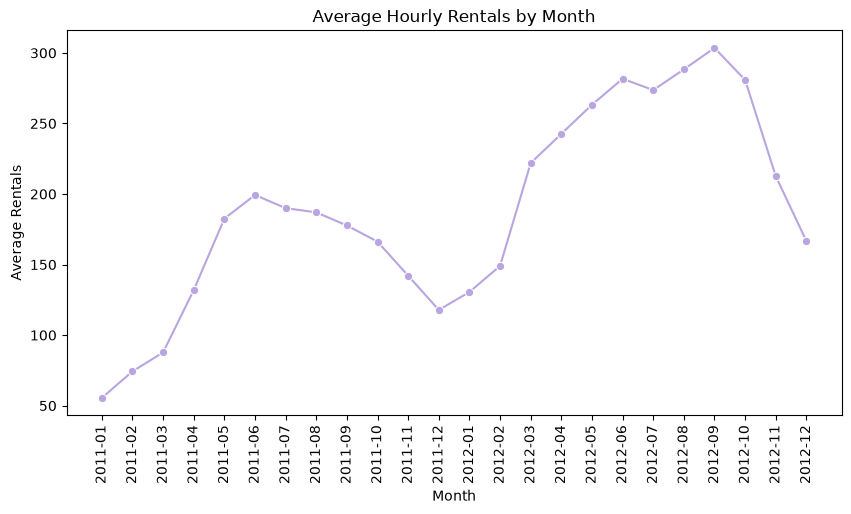

Months: 24
Records per month: min 649 | max 744
Total records: 17379


In [31]:
# Month label like 2011-01, 2011-02, ... (safe to recreate)
data_prep['year_month'] = data_prep['dteday'].dt.to_period('M').astype(str)

monthly = (
    data_prep.groupby('year_month')
    .agg(avg_rentals=('cnt', 'mean'), records=('cnt', 'count'))
    .reset_index()
)

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly, x='year_month', y='avg_rentals', marker='o', color='#B9A5E0')
plt.title('Average Hourly Rentals by Month')
plt.xlabel('Month')
plt.ylabel('Average Rentals')
plt.xticks(rotation=90)
plt.show()

print('Months:', len(monthly))
print('Records per month: min', monthly['records'].min(), '| max', monthly['records'].max())
print('Total records:', monthly['records'].sum())

In [32]:
test_start = pd.Timestamp('2012-10-01')

train_df = data_prep[data_prep['dteday'] < test_start].copy()
test_df = data_prep[data_prep['dteday'] >= test_start].copy()

print('Train:', train_df['dteday'].min().date(), '-', train_df['dteday'].max().date(), '| records:', len(train_df))
print('Test: ', test_df['dteday'].min().date(), '-', test_df['dteday'].max().date(), '| records:', len(test_df))
print('Total:', len(train_df) + len(test_df))
print('Test share, %:', round(len(test_df) / len(data_prep) * 100, 1))
print('Mean cnt  train:', round(train_df['cnt'].mean(), 1), '| test:', round(test_df['cnt'].mean(), 1))

Train: 2011-01-01 - 2012-09-30 | records: 15211
Test:  2012-10-01 - 2012-12-31 | records: 2168
Total: 17379
Test share, %: 12.5
Mean cnt  train: 185.2 | test: 219.2


**_2.1 Time-Based Split_**

Average hourly demand follows a clear seasonal pattern in both years, and every month of 2012 is higher than the same month of 2011. The data are split by time: the training set contains all records before 2012-10-01 (2011-01-01 to 2012-09-30, 15,211 records), and the test set contains the last three months (2012-10-01 to 2012-12-31, 2,168 records, 12.5% of the data). The test set is not used until the final evaluation.

Average rentals are higher in the test set (219.2) than in the training set (185.2), even though the test months are autumn and early winter. This reflects the higher demand level in 2012 compared with 2011, so the effect of the year must be handled carefully when selecting features.

Limitation: the test set covers only three months (October to December), so test metrics describe the model in this period and may differ for other seasons.

**_2.2 Time-Series Cross-Validation_**

Model selection inside the training set will use time-series cross-validation: each fold trains on earlier data and validates on the next period, so the future never leaks into the past. The test set is not used for model selection.

The folds are built on whole days. The sorted list of unique training dates is split in time order into five folds, so every day belongs entirely to either the training part or the validation part, and no rows are discarded. Splitting by rows would cut the boundary day in the middle and put the same day into both parts.

Three points need attention:

- Fold 1 trains on only about 3.5 months of winter and early spring 2011 and validates on spring and summer, so its score will be weaker and less reliable.
- Folds 1-3 train only on 2011, so `yr` is constant (0) in their training parts and these folds cannot show whether `yr` is useful. Folds 4 and 5 contain 2012 in training and are closest to the final test situation.
- Neighboring days are similar (weather, demand level), so the validation scores are still somewhat optimistic. Whole-day folds only guarantee that no single day is shared.

Metrics are reported per fold, not only as an average.

In [33]:
from sklearn.model_selection import TimeSeriesSplit

# Rows must be in time order
train_df = train_df.sort_values(['dteday', 'hr']).reset_index(drop=True)

# Folds are built on whole days: split the sorted list of unique dates in time order
dates = np.sort(train_df['dteday'].unique())
print('Unique days in train:', len(dates))

tscv = TimeSeriesSplit(n_splits=5)

cv_folds = []
for fold, (fit_d, val_d) in enumerate(tscv.split(dates), start=1):
    fit_dates, val_dates = dates[fit_d], dates[val_d]

    fit_idx = np.where(train_df['dteday'].isin(fit_dates))[0]
    val_idx = np.where(train_df['dteday'].isin(val_dates))[0]
    cv_folds.append((fit_idx, val_idx))

    fit_part = train_df.iloc[fit_idx]
    val_part = train_df.iloc[val_idx]
    shared_days = set(fit_dates) & set(val_dates)
    print(f"Fold {fold}: fit {fit_part['dteday'].min().date()} - {fit_part['dteday'].max().date()} ({len(fit_part)} rows)"
          f" | validate {val_part['dteday'].min().date()} - {val_part['dteday'].max().date()} ({len(val_part)} rows)"
          f" | shared days: {len(shared_days)}")

Unique days in train: 639
Fold 1: fit 2011-01-01 - 2011-04-19 (2522 rows) | validate 2011-04-20 - 2011-08-03 (2544 rows) | shared days: 0
Fold 2: fit 2011-01-01 - 2011-08-03 (5066 rows) | validate 2011-08-04 - 2011-11-17 (2527 rows) | shared days: 0
Fold 3: fit 2011-01-01 - 2011-11-17 (7593 rows) | validate 2011-11-18 - 2012-03-02 (2533 rows) | shared days: 0
Fold 4: fit 2011-01-01 - 2012-03-02 (10126 rows) | validate 2012-03-03 - 2012-06-16 (2541 rows) | shared days: 0
Fold 5: fit 2011-01-01 - 2012-06-16 (12667 rows) | validate 2012-06-17 - 2012-09-30 (2544 rows) | shared days: 0


### 3. Feature Selection

**_3.1 Candidate Features_**

Some columns are clearly not features: `cnt` is the target, `casual` and `registered` leak the target (`cnt = casual + registered`), `instant` is a row number, and `dteday` was needed only for the split. The columns created during the analysis (`year`, `year_month`, `timestamp`, `wind_group`, `atemp_group`) are also excluded, because they duplicate other columns or are used for labels only.

All other columns are kept as candidates. The usefulness of `yr`, `atemp` (together with `temp`), `weekday`, `holiday`, `windspeed` and `windspeed_zero` will be checked during model comparison, not decided from a single plot.

In [34]:
target = 'cnt'
leakage_cols = ['casual', 'registered']
id_cols = ['instant', 'dteday']
helper_cols = ['year', 'year_month', 'timestamp', 'wind_group', 'atemp_group']

excluded = [target] + leakage_cols + id_cols + helper_cols
candidate_features = [c for c in train_df.columns if c not in excluded]

print('Candidate features:', len(candidate_features))
print(candidate_features)

# Every excluded name must exist in the table (guards against typos)
print('Excluded names not found in the table:', [c for c in excluded if c not in train_df.columns])

Candidate features: 13
['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'windspeed_zero']
Excluded names not found in the table: []


**_3.2 Year Effect_**

Average rentals are higher in 2012 than in 2011, and `yr` captures this. How to handle it depends on the shape of the difference: if the gap is stable, `yr` acts as a simple shift, but if it changes between months, the effect of the year depends on the season. To avoid looking at the test set, we use only the training data and compare January to September, the months present in both years.

In [35]:
months_both = train_df[train_df['mnth'] <= 9]

by_month = months_both.groupby(['mnth', 'year'])['cnt'].mean().unstack('year').round(1)
by_month['ratio_2012_to_2011'] = (by_month[2012] / by_month[2011]).round(2)
by_month['diff_2012_minus_2011'] = (by_month[2012] - by_month[2011]).round(1)

print(by_month)
print('Min records per month-year:', months_both.groupby(['mnth', 'year']).size().min())

year   2011   2012  ratio_2012_to_2011  diff_2012_minus_2011
mnth                                                        
1      55.5  130.6                2.35                  75.1
2      74.3  149.0                2.01                  74.7
3      87.7  221.9                2.53                 134.2
4     131.9  242.7                1.84                 110.8
5     182.6  263.3                1.44                  80.7
6     199.3  281.7                1.41                  82.4
7     190.0  273.7                1.44                  83.7
8     187.0  288.3                1.54                 101.3
9     177.7  303.6                1.71                 125.9
Min records per month-year: 649


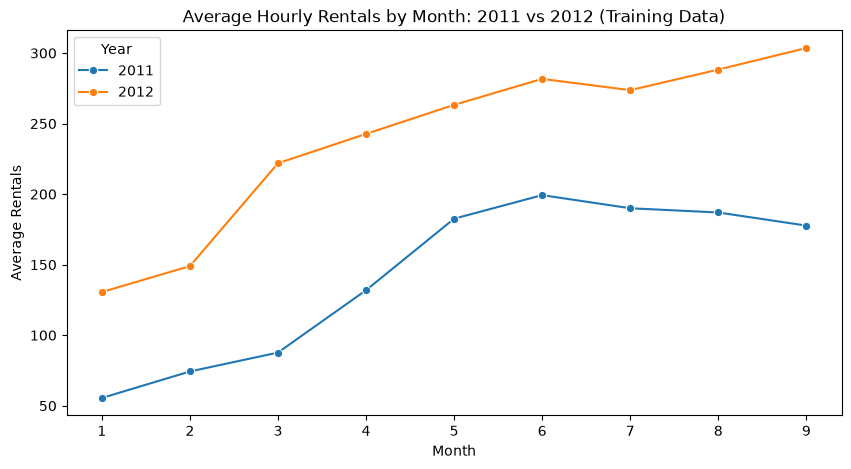

In [36]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=by_month[[2011, 2012]], marker='o', dashes=False)
plt.title('Average Hourly Rentals by Month: 2011 vs 2012 (Training Data)')
plt.xlabel('Month')
plt.ylabel('Average Rentals')
plt.xticks(range(1, 10))
plt.legend(title='Year')
plt.show()

Average rentals are higher in 2012 than in 2011 in every month from January to September, but the gap is not stable. The ratio ranges from 1.41 (June) to 2.53 (March) and the difference from 74.7 (February) to 134.2 (March); the spread is about 1.8 times for both, so neither measure is constant. The seasonal shape also differs: in 2011 demand peaks in June and then declines, while in 2012 it keeps growing until September. The reasons are unknown. The table does not cover October to December, because the training set has only 2011 for these months.

Decision: keep `yr` unchanged as a candidate feature. Its usefulness will be checked during model comparison (with and without `yr`) on folds 4 and 5 only, because in folds 1-3 `yr` is constant in the training part. The interaction between the year and the month, and the log transformation of the target, are considered in the next steps.

**_3.3 Overlaps Between Candidate Features_**

Some candidate features duplicate each other. Duplicates make coefficients of linear models unstable and add noise, while tree-based models are much less affected. Using only the training data, we check three groups: `temp` and `atemp` (after the correction of `atemp` in section 1.3), `season` and `mnth`, and `weekday`, `workingday` and `holiday`.

In [37]:
num_cols = ['temp', 'atemp', 'hum', 'windspeed', 'windspeed_zero']
print(train_df[num_cols].corr().round(3))

                 temp  atemp    hum  windspeed  windspeed_zero
temp            1.000  0.992 -0.074     -0.032          -0.013
atemp           0.992  1.000 -0.057     -0.066           0.010
hum            -0.074 -0.057  1.000     -0.283           0.105
windspeed      -0.032 -0.066 -0.283      1.000          -0.586
windspeed_zero -0.013  0.010  0.105     -0.586           1.000


In [38]:
ct = pd.crosstab(train_df['mnth'], train_df['season'])
print(ct)

off_share = (1 - ct.max(axis=1).sum() / ct.values.sum()) * 100
print('Records outside the main season of their month, %:', round(off_share, 1))

season     1     2     3    4
mnth                         
1       1429     0     0    0
2       1341     0     0    0
3        949   524     0    0
4          0  1437     0    0
5          0  1488     0    0
6          0   960   480    0
7          0     0  1488    0
8          0     0  1475    0
9          0     0  1053  384
10         0     0     0  743
11         0     0     0  719
12       261     0     0  480
Records outside the main season of their month, %: 10.8


In [39]:
rule = (train_df['weekday'].between(1, 5) & (train_df['holiday'] == 0)).astype(int)
mismatch = train_df[rule != train_df['workingday']]

print('Records where workingday differs from the rule:', len(mismatch))
print(mismatch[['dteday', 'weekday', 'holiday', 'workingday']].drop_duplicates('dteday').to_string(index=False))

Records where workingday differs from the rule: 0
Empty DataFrame
Columns: [dteday, weekday, holiday, workingday]
Index: []


The correlation between `temp` and `atemp` in the training data is 0.992, so they are almost interchangeable. `windspeed_zero` is correlated with `windspeed` (-0.586) because it is derived from it, and it is almost unrelated to the other features.

`season` is almost determined by `mnth`: four months (March, June, September, December) contain two seasons, and only 10.8% of records lie outside the main season of their month.

`workingday` follows the rule "Monday to Friday and not a holiday" in every record. All holidays fall on weekdays, so `workingday` is an exact linear combination of `weekday` and `holiday`. This is harmless for tree-based models, and `workingday` is useful for them because it makes the `hr × workingday` interaction easier to find. For linear models, using all dummy columns of `weekday` together with `holiday` and `workingday` would create perfect multicollinearity.

Decision: all 13 candidates stay for now. For `temp` and `atemp`, three variants (`temp`, `atemp`, both) are compared. For linear models, only one of `season` and `mnth` is used, and the encoding of `weekday`, `workingday` and `holiday` avoids exact dependence. The final choice is made during model comparison.

### 4. Feature Engineering

Tree-based models can find thresholds and interactions on their own, so they use the original columns. Linear models need the shape of the relationship to be prepared explicitly. We create two kinds of features that do not depend on the data, so they cannot leak information from the test set:

- `hr_workingday`: the hour and the working-day flag as one label (for example `08_1`). In the EDA, the daily curve has two sharp peaks on working days and one wide peak on non-working days, so the effect of the hour depends on the day type. A single pair of sine and cosine cannot describe two peaks per day, so the hour is not encoded cyclically.
- `mnth_sin` and `mnth_cos`: cyclic encoding of the month, so that December and January are neighbors. The seasonal curve over a year has one peak, which one pair of sine and cosine can describe.

Encoding of categories into dummy columns and scaling are done later inside a pipeline, because they must be fitted on the training set only.

In [40]:
for df in (train_df, test_df):
    df['hr_workingday'] = df['hr'].astype(str).str.zfill(2) + '_' + df['workingday'].astype(str)
    df['mnth_sin'] = np.sin(2 * np.pi * df['mnth'] / 12)
    df['mnth_cos'] = np.cos(2 * np.pi * df['mnth'] / 12)

print(train_df[['hr', 'workingday', 'hr_workingday', 'mnth', 'mnth_sin', 'mnth_cos']].head())

   hr  workingday hr_workingday  mnth  mnth_sin  mnth_cos
0   0           0          00_0     1       0.5  0.866025
1   1           0          01_0     1       0.5  0.866025
2   2           0          02_0     1       0.5  0.866025
3   3           0          03_0     1       0.5  0.866025
4   4           0          04_0     1       0.5  0.866025


In [41]:
# hr_workingday: how many categories, how small is the smallest one, any unseen in test
train_cats = set(train_df['hr_workingday'])
test_cats = set(test_df['hr_workingday'])
print('Categories in train:', len(train_cats))
print('Categories in test only:', sorted(test_cats - train_cats))
print('Smallest category in train (rows):', train_df['hr_workingday'].value_counts().min())

# mnth_sin / mnth_cos: one row per month
print(train_df[['mnth', 'mnth_sin', 'mnth_cos']].drop_duplicates().sort_values('mnth').round(3).to_string(index=False))

Categories in train: 48
Categories in test only: []
Smallest category in train (rows): 192
 mnth  mnth_sin  mnth_cos
    1     0.500     0.866
    2     0.866     0.500
    3     1.000     0.000
    4     0.866    -0.500
    5     0.500    -0.866
    6     0.000    -1.000
    7    -0.500    -0.866
    8    -0.866    -0.500
    9    -1.000    -0.000
   10    -0.866     0.500
   11    -0.500     0.866
   12    -0.000     1.000


Checks: `hr_workingday` has 48 categories in the training set, the test set contains no category that is absent from the training set, and the smallest category has 192 training rows. For `mnth_sin` and `mnth_cos`, December and January are neighbors on the circle. One pair of sine and cosine describes a smooth yearly curve and may not capture the sharp rise in spring, which will be checked during model comparison.

**_4.2 Feature Sets_**

Two feature sets are defined, because tree-based and linear models have different needs.

- **Tree-based models** use all 13 original candidates unchanged. Overlapping features do not harm them much, and trees can find thresholds and interactions on their own.
- **Linear models** use a narrower set that avoids the overlaps found in section 3.3: the label `hr_workingday` (as dummy columns) replaces `hr` and `workingday`, because the dummy columns of the working-day type sum exactly to `workingday`; `mnth_sin` and `mnth_cos` replace `mnth` and `season`; `temp` is used without `atemp`. `weekday` is left out of the base set, because together with `hr_workingday` and `holiday` it would create an exact linear dependence, and its effect in the EDA was small.

These are starting sets. The usefulness of individual features (`atemp`, `weekday`, `yr`, `holiday`, `windspeed`, `windspeed_zero`) is checked during model comparison.

In [42]:
features_tree = list(candidate_features)

linear_categorical = ['hr_workingday', 'weathersit']
linear_numeric = ['yr', 'holiday', 'temp', 'hum', 'windspeed', 'windspeed_zero', 'mnth_sin', 'mnth_cos']
features_linear = linear_categorical + linear_numeric

print('Tree features:', len(features_tree))
print('Linear features:', len(features_linear))

# All names must exist in both tables, and none may be the target or a leakage column
for name, cols in (('tree', features_tree), ('linear', features_linear)):
    missing = [c for c in cols if c not in train_df.columns or c not in test_df.columns]
    forbidden = [c for c in cols if c in ['cnt', 'casual', 'registered']]
    print(name, '| missing:', missing, '| forbidden:', forbidden)

# Size of the linear matrix after dummy encoding (training set only, nothing is fitted)
dummies = pd.get_dummies(train_df[features_linear], columns=linear_categorical, drop_first=True)
print('Linear matrix after dummy encoding:', dummies.shape)

Tree features: 13
Linear features: 10
tree | missing: [] | forbidden: []
linear | missing: [] | forbidden: []
Linear matrix after dummy encoding: (15211, 57)


### 5. Target Variable and Scaling

**_5.1 Target Distribution_**

In the EDA, `cnt` was right-skewed (mean 189.46, median 142). A log transformation, `log1p(cnt) = log(1 + cnt)`, can make the distribution more symmetric, which sometimes helps linear models. Whether it actually improves the results is checked during model comparison, so both versions of the target are prepared. Here we compare the distribution of the two versions using the training set only.

In [43]:
y_train_raw = train_df['cnt']
y_train_log = np.log1p(y_train_raw)

summary = pd.DataFrame({
    'cnt': [y_train_raw.mean(), y_train_raw.median(), y_train_raw.skew()],
    'log1p(cnt)': [y_train_log.mean(), y_train_log.median(), y_train_log.skew()]
}, index=['mean', 'median', 'skewness']).round(3)

print(summary)

              cnt  log1p(cnt)
mean      185.225       4.552
median    138.000       4.934
skewness    1.299      -0.819


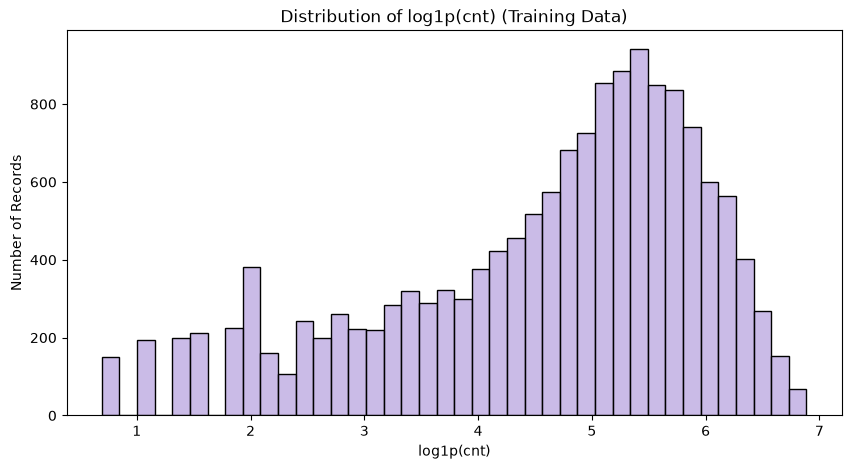

In [44]:
plt.figure(figsize=(10, 5))
sns.histplot(y_train_log, bins=40, color='#B9A5E0')
plt.title('Distribution of log1p(cnt) (Training Data)')
plt.xlabel('log1p(cnt)')
plt.ylabel('Number of Records')
plt.show()

In the training set, `cnt` has a skewness of 1.299 (mean 185.2, median 138). After `log1p`, the skewness is -0.819 (mean 4.55, median 4.93): the asymmetry is smaller in absolute value, but its direction is reversed, and a long left tail appears. This tail comes from hours with few rentals, mostly at night, because the logarithm stretches small values. The small gaps and the spike near 2 on the histogram are most likely artifacts of integer counts and bin width. So the logarithm is not a clean fix for the skewness.

Two practical points. A model trained on `log1p(cnt)` minimizes relative errors, so quiet night hours weigh as much as rush hours. Back-transformed predictions (`expm1`) tend to underestimate the mean.

Decision: both versions of the target, `cnt` and `log1p(cnt)`, are prepared, and the choice is made during model comparison. All metrics are calculated on the original scale after back-transformation.

In [45]:
# Milder alternative: square root
print('Skewness of sqrt(cnt):', round(np.sqrt(y_train_raw).skew(), 3))

# Both versions of the target for train and test
y_train, y_test = train_df['cnt'], test_df['cnt']
y_train_log, y_test_log = np.log1p(y_train), np.log1p(y_test)

# Back-transformation must restore the original values
print('Back-transformation exact:',
      np.allclose(np.expm1(y_train_log), y_train),
      np.allclose(np.expm1(y_test_log), y_test))
print('Shapes:', y_train.shape, y_test.shape)

Skewness of sqrt(cnt): 0.296
Back-transformation exact: True True
Shapes: (15211,) (2168,)


The square root is a milder transformation: the skewness of `sqrt(cnt)` is 0.296, closer to zero than both `cnt` (1.299) and `log1p(cnt)` (-0.819), and it does not create a pronounced left tail. Skewness describes only the shape of the target, so it does not show which version gives better predictions.

Decision: three versions of the target, `cnt`, `sqrt(cnt)` and `log1p(cnt)`, are prepared, and the choice is made during model comparison. All metrics are calculated on the original scale after back-transformation. For `sqrt(cnt)`, negative predictions must be clipped to zero before squaring.

In [46]:
y_train_sqrt, y_test_sqrt = np.sqrt(y_train), np.sqrt(y_test)
print('Back-transformation exact (sqrt):',
      np.allclose(y_train_sqrt ** 2, y_train), np.allclose(y_test_sqrt ** 2, y_test))

print(pd.Series({
    'cnt': y_train.skew(),
    'sqrt(cnt)': y_train_sqrt.skew(),
    'log1p(cnt)': y_train_log.skew()
}).round(3))

Back-transformation exact (sqrt): True True
cnt           1.299
sqrt(cnt)     0.296
log1p(cnt)   -0.819
dtype: float64


**_5.2 Scaling_**

Scaling is needed only for linear models; tree-based models do not need it. The features `temp`, `hum` and `windspeed` are already normalized to about 0-1, and `mnth_sin` and `mnth_cos` lie between -1 and 1. For ordinary linear regression the scale of features does not change the predictions, but it matters for regularized models (Ridge, Lasso), where the penalty is the same for all coefficients. We check how different the scales are in the training set.

In [47]:
scale_candidates = ['temp', 'hum', 'windspeed', 'mnth_sin', 'mnth_cos']
print(train_df[scale_candidates].agg(['min', 'max', 'mean', 'std']).round(3))

print(train_df[['yr', 'holiday', 'windspeed_zero']].agg(['min', 'max']))

       temp    hum  windspeed  mnth_sin  mnth_cos
min   0.020  0.080      0.000    -1.000    -1.000
max   1.000  1.000      0.851     1.000     1.000
mean  0.513  0.626      0.192     0.058    -0.120
std   0.196  0.194      0.122     0.720     0.681
     yr  holiday  windspeed_zero
min   0        0               0
max   1        1               1


In the training set, `temp`, `hum` and `windspeed` have standard deviations of 0.196, 0.194 and 0.122, while `mnth_sin` and `mnth_cos` have 0.720 and 0.681, so the scales differ by a factor of 3.5 to 6. This does not change the predictions of ordinary linear regression, but it matters for regularized models (Ridge, Lasso), where features with a small spread are penalized more strongly. Humidity has no zeros left (minimum 0.080), and `yr`, `holiday` and `windspeed_zero` are binary.

Decision: apply `StandardScaler` to the five continuous features (`temp`, `hum`, `windspeed`, `mnth_sin`, `mnth_cos`) in the pipeline of linear models only. Binary columns and dummy columns are not scaled, and tree-based models receive no scaling. The scaler is fitted on the training part of each cross-validation fold, never on validation or test data.

### 6. Final Checks and Saving

**_6.1 Preprocessor for Linear Models_**

The preprocessing of linear models is collected in one `ColumnTransformer`: the categorical features (`hr_workingday`, `weathersit`) are encoded as dummy columns, the five continuous features are standardized, and the binary features are passed unchanged. It is fitted on the training set only and then applied to the test set. Tree-based models use the original columns, so they need no separate preprocessor.

In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

continuous = ['temp', 'hum', 'windspeed', 'mnth_sin', 'mnth_cos']
binary = ['yr', 'holiday', 'windspeed_zero']

linear_prep = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first'), linear_categorical),
        ('num', StandardScaler(), continuous),
        ('bin', 'passthrough', binary),
    ],
    sparse_threshold=0
)

X_train_lin = linear_prep.fit_transform(train_df[features_linear])
X_test_lin = linear_prep.transform(test_df[features_linear])

print('Shapes:', X_train_lin.shape, X_test_lin.shape)

# Columns 49-53 are the five standardized features (47 + 2 dummy columns come first)
print('Train mean:', X_train_lin[:, 49:54].mean(axis=0).round(3))
print('Train std: ', X_train_lin[:, 49:54].std(axis=0).round(3))
print('Test mean: ', X_test_lin[:, 49:54].mean(axis=0).round(3))
print('NaN values:', np.isnan(X_train_lin).sum(), np.isnan(X_test_lin).sum())

Shapes: (15211, 57) (2168, 57)
Train mean: [ 0.  0. -0.  0. -0.]
Train std:  [1. 1. 1. 1. 1.]
Test mean:  [-0.642  0.088 -0.093 -0.703  1.34 ]
NaN values: 0 0


Checks: the transformed training set has 57 columns, the five standardized features have mean 0 and standard deviation 1 on the training set, and there are no missing values. On the test set the means are not zero (for example -0.642 for `temp`, about 0.64 standard deviations below the training mean), because the scaler was fitted on the training set only. The test period (October to December) is colder than the training period on average, which must be kept in mind when reading test metrics.

**_6.2 Final Checks and Reproducibility_**

Before saving, we run final checks on the prepared tables. The features created by hand (the merge of `weathersit` 4 into 3, `hr_workingday`, `mnth_sin` and `mnth_cos`) must also be built from raw input values in the future API, so they are collected in one function. We check that this function reproduces exactly the columns used in the notebook when applied to the raw file. The corrections of historical data quality problems (humidity on 2011-03-10 and `atemp` on two days) are not part of the function, because they clean existing records and new measurements are expected to be correct.

In [49]:
checks = {
    'NaN in tree features (train, test)': (int(train_df[features_tree].isna().sum().sum()),
                                           int(test_df[features_tree].isna().sum().sum())),
    'Train ends before test starts': train_df['dteday'].max() < test_df['dteday'].min(),
    'Target or leakage columns in features': [c for c in features_tree + features_linear
                                              if c in ['cnt', 'casual', 'registered']],
    'weathersit values (train, test)': (sorted(train_df['weathersit'].unique()),
                                        sorted(test_df['weathersit'].unique())),
    'Records train + test': len(train_df) + len(test_df),
}
for name, value in checks.items():
    print(name, ':', value)

NaN in tree features (train, test) : (0, 0)
Train ends before test starts : True
Target or leakage columns in features : []
weathersit values (train, test) : ([np.int64(1), np.int64(2), np.int64(3)], [np.int64(1), np.int64(2), np.int64(3)])
Records train + test : 17379


In [50]:
def add_features(df):
    out = df.copy()
    out['weathersit'] = out['weathersit'].replace(4, 3)
    out['hr_workingday'] = out['hr'].astype(str).str.zfill(2) + '_' + out['workingday'].astype(str)
    out['mnth_sin'] = np.sin(2 * np.pi * out['mnth'] / 12)
    out['mnth_cos'] = np.cos(2 * np.pi * out['mnth'] / 12)
    return out

check_cols = ['weathersit', 'hr_workingday', 'mnth_sin', 'mnth_cos']

for name, table in (('train', train_df), ('test', test_df)):
    raw_rows = data.set_index('instant').loc[table['instant']].reset_index()
    rebuilt = add_features(raw_rows)
    same = {c: bool(np.array_equal(rebuilt[c].values, table[c].values)) for c in check_cols}
    print(name, same)

train {'weathersit': True, 'hr_workingday': True, 'mnth_sin': True, 'mnth_cos': True}
test {'weathersit': True, 'hr_workingday': True, 'mnth_sin': True, 'mnth_cos': True}


Checks: there are no missing values in the features, the training period ends before the test period starts, the features contain no target or leakage columns, `weathersit` has only the values 1, 2 and 3 in both sets, and the two sets contain 17,379 records in total. The function `add_features` applied to the raw file reproduces exactly the columns `weathersit`, `hr_workingday`, `mnth_sin` and `mnth_cos` used in the notebook, for both the training and the test set.

**_6.3 Saving_**

The prepared tables, the cross-validation folds and the fitted preprocessor are saved so that the modeling stage starts from exactly the same data. The columns `casual` and `registered` are not saved, because they leak the target. The fold indices refer to the row order of `train.csv`, so this file must not be re-sorted. The raw file is not changed. The saved preprocessor is fitted on the training set only and will be fitted again when the final model is trained on all data.

In [51]:
from pathlib import Path
import joblib

processed_dir = Path('../data/processed')
models_dir = Path('../models')
processed_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(exist_ok=True)

save_cols = ['instant', 'dteday'] + features_tree + ['hr_workingday', 'mnth_sin', 'mnth_cos', 'cnt']

train_df[save_cols].to_csv(processed_dir / 'train.csv', index=False)
test_df[save_cols].to_csv(processed_dir / 'test.csv', index=False)
joblib.dump(cv_folds, processed_dir / 'cv_folds.joblib')
joblib.dump(linear_prep, models_dir / 'linear_preprocessor.joblib')

# Reload everything and verify
train_back = pd.read_csv(processed_dir / 'train.csv', parse_dates=['dteday'])
test_back = pd.read_csv(processed_dir / 'test.csv', parse_dates=['dteday'])
folds_back = joblib.load(processed_dir / 'cv_folds.joblib')
prep_back = joblib.load(models_dir / 'linear_preprocessor.joblib')

print('Saved columns:', len(save_cols))
print('Shapes:', train_back.shape, test_back.shape)
print('Same cnt and row order:', train_back['cnt'].equals(train_df['cnt']), test_back['cnt'].equals(test_df['cnt']))
print('Folds identical:', all(np.array_equal(a[0], b[0]) and np.array_equal(a[1], b[1])
                              for a, b in zip(cv_folds, folds_back)))
print('Preprocessor reproduces X_test:', np.allclose(prep_back.transform(test_back[features_linear]), X_test_lin))
print('Leakage columns saved:', [c for c in ['casual', 'registered'] if c in train_back.columns])

Saved columns: 19
Shapes: (15211, 19) (2168, 19)
Same cnt and row order: True False
Folds identical: True
Preprocessor reproduces X_test: True
Leakage columns saved: []


In [53]:
for name, back, orig in (('train', train_back, train_df), ('test', test_back, test_df)):
    diff_cols = []
    for c in save_cols:
        a = back[c].reset_index(drop=True)
        b = orig[c].reset_index(drop=True)
        if pd.api.types.is_numeric_dtype(a) and pd.api.types.is_numeric_dtype(b):
            ok = np.allclose(a.to_numpy(), b.to_numpy())
        else:
            ok = (a.astype(str) == b.astype(str)).all()
        if not ok:
            diff_cols.append(c)
    print(name, '| columns whose values differ:', diff_cols)

train | columns whose values differ: []
test | columns whose values differ: []


### 7. Data Preparation Summary

**Data quality**
- Zero wind speed (2,180 records, about 12.5%) is kept unchanged. Zeros are more frequent at night and follow the daily cycle of wind, so they most likely mean very weak wind. A `windspeed_zero` flag is a candidate feature.
- Zero humidity on 2011-03-10 (22 records) is treated as missing and filled with the median humidity of records with the same `weathersit`.
- `atemp` is constant (0.2424) on 2012-08-17 and 2012-12-29 (48 records) and is replaced with predictions from a linear model on `temp` (MAE 0.016).
- 165 missing hours (about 0.94%) are not restored. Part of the night gaps may be hours with zero rentals, which the data cannot confirm.
- `weathersit = 4` (3 records) is merged into category 3. `holiday` is kept unchanged.

**Split**
- Time-based split: training 2011-01-01 to 2012-09-30 (15,211 records), test 2012-10-01 to 2012-12-31 (2,168 records, 12.5%).
- Five cross-validation folds built on whole days inside the training set.

**Features and target**
- 13 candidate features; tree-based models use them unchanged, linear models use 10 features (57 columns after encoding) with `hr_workingday`, `mnth_sin` and `mnth_cos`.
- Three versions of the target are prepared: `cnt`, `sqrt(cnt)` and `log1p(cnt)`. Metrics are calculated on the original scale.
- Linear models standardize five continuous features; the preprocessor is fitted on the training part only.

**Limitations**
- The test set covers only October to December, so its metrics may not represent other seasons, and its average temperature is lower than in training.
- The median humidity and the `atemp` formula were fitted on the full dataset (0.13% and 0.28% of records, the target is not used).
- The first folds train only on 2011 and cannot show the effect of `yr`; its usefulness is checked on folds 4 and 5.
- The reasons for the differences between 2011 and 2012, for the zero wind speed and for the missing hours are unknown.